# Demo 3 · Калібрування: чотири типові помилки в цифрах

До слайдів **«Пайплайн калібрування»** і **«Типові помилки калібрування»**.

Слайд стверджує чотири речі: замало знімків → нестабільна `K`; дошка лише в центрі → дисторсія на краях невідома; один і той самий кут → система вироджена; низький RMSE ≠ точне калібрування.

Щоб перевірити це **чесно**, треба знати істинну `K`. Для реальної камери її не знає ніхто — тому тут **віртуальна камера**: `K` і дисторсію задаємо самі, кадри мішені рендеримо, а детектор кутів і `cv2.calibrateCamera` — справжні. Тоді помилка калібрування — це просто різниця між оцінкою й істиною.

Одна метрика на весь ноутбук — **промах променя**: на скільки мрад модель помиляється з напрямком для пікселя кадру. Це те, що в полі перетворюється на метри промаху: 1 мрад — 1 м на 1 км. Фокусна віртуальної камери — 1000 px, тож 1 px ≈ 1 мрад, і піксельні й кутові числа читаються однаково.

> Як зробити те саме на власних знімках — у кінці.

## 1 · Віртуальна камера

Камера 1280×720, `f = 1000 px`, головна точка трохи зсунута від центру, помітна бочкоподібна дисторсія (`k1 = −0.25`) — типовий ширококутний модуль. Мішень — шахівниця 10×7 клітинок по 34 мм, тобто **9×6 внутрішніх кутів**; для порівняння ще ChArUco 9×6.

Рендер простий: для кожного пікселя кадру беремо його промінь (інверсія істинної дисторсії) і перетинаємо з площиною дошки. Плюс легке розмиття й шум сенсора, щоб детектор працював як на справжньому фото.

**Покроково — налаштування:**

1. Імпорти: OpenCV, NumPy, matplotlib, а також `dataclass`, `json`, `datetime`, які знадобляться для паспорта.
2. **Істинна модель камери** — `K_TRUE` (`fx = fy = 1000`, `cx = 646.5`, `cy = 354.8`) і `DIST_TRUE` (`k1, k2, p1, p2, k3`). Це «правильна відповідь», з якою потім порівнюємо кожне калібрування.
3. Параметри мішеней. Шахівниця 10×7 клітинок по 34 мм дає 9×6 = 54 внутрішні кути. ChArUco 9×6 клітинок по 40 мм, маркери 30 мм, словник `DICT_5X5_250`.
4. Генератор `rng` із `SEED = 0` і `reseed(section)`. Кожен розділ на початку викликає `reseed(k)` і отримує власний генератор `SEED + k`, тому перезапуск однієї клітинки дає ті самі цифри, що й прогін усього ноутбука.
5. Створюємо теку для артефактів і задаємо темний стиль графіків.

In [47]:
import json, time, datetime
from dataclasses import dataclass
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

W, H = 1280, 720
K_TRUE = np.array([[1000.0, 0, 646.5],
                   [0, 1000.0, 354.8],
                   [0,      0,     1]])
DIST_TRUE = np.array([-0.25, 0.09, 0.0004, -0.0001, -0.016])   # k1 k2 p1 p2 k3
FX_TRUE = K_TRUE[0, 0]

# мішені
SQUARES, SQUARE_M = (10, 7), 0.034                          # шахівниця: клітинок і крок
CORNERS = (SQUARES[0] - 1, SQUARES[1] - 1)                  # 9×6 ВНУТРІШНІХ кутів
CH_SQUARES, CH_SQUARE_M, CH_MARKER_M = (9, 6), 0.040, 0.030  # ChArUco
CH_DICT = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_5X5_250)

SEED = 0
rng = np.random.default_rng(SEED)


def reseed(section):
    '''Свій генератор на кожен розділ: перезапуск однієї клітинки дає ті самі цифри, що й прогін усього ноутбука.'''
    global rng
    rng = np.random.default_rng(SEED + section)

# паспорт пишемо в artifacts/ у корені репозиторію, як і решта даних курсу
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lessons").is_dir()), Path.cwd())
OUT_DIR = REPO_ROOT / "artifacts" / "calibration_demo"; OUT_DIR.mkdir(parents=True, exist_ok=True)

# стиль графіків
DARK, PANEL, TXT, MUTED = "#0f1115", "#181b21", "#d7dbe0", "#8a8f98"
EMERALD, AMBER, RED = "#34d399", "#fbbf24", "#f87171"
GREEN_CMAP = LinearSegmentedColormap.from_list("panel-emerald", [PANEL, "#0f4a38", "#1f8a63"])
plt.rcParams.update({"figure.facecolor": DARK, "axes.facecolor": PANEL, "axes.edgecolor": MUTED,
                     "axes.labelcolor": TXT, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": TXT,
                     "axes.grid": True, "grid.color": "#2a2f38", "grid.linestyle": ":", "legend.frameon": False,
                     "font.size": 10, "figure.dpi": 100, "axes.titleweight": "bold"})
print("OpenCV", cv2.__version__)

OpenCV 4.11.0


**Покроково — віртуальна камера й рендер кадру:**

1. `chessboard_texture()` малює шахівницю як зображення з роздільністю 3000 px на метр і білим полем 2 см. Текстуру ChArUco генерує `CharucoBoard.generateImage` у тому самому масштабі.
2. `BOARD_CENTER` — центр кожної дошки в її власній системі координат. Позу задаємо саме через центр.
3. `OBJ_CHESS` — 3D-координати 54 внутрішніх кутів (`Z = 0`, у метрах). `+1`, бо перший внутрішній кут стоїть на одну клітинку від краю дошки.
4. `undistort_normalized()` обертає модель дисторсії ітерацією нерухомої точки: піксель → нормалізовані `(x, y)` без дисторсії.
5. `RAYS` — промінь `(x, y, 1)` для кожного з 1280×720 пікселів за **істинною** моделлю. Рахується один раз, і через нього дисторсія «вшивається» в кадр: детектор бачить вигнуті лінії, як на справжньому фото. `BACKGROUND` — градієнтний фон навколо дошки.
6. `pose()` будує `R` (нахил на `tilt°` навколо осі в площині дошки, потім поворот `roll°`) і `t` так, щоб центр дошки проектувався в заданий піксель на глибині `z`.
7. `render()`:
   - площина дошки `[r1 r2 t]` — це гомографія `(X, Y, 1) → камера`;
   - її обернена переводить промінь кожного пікселя в точку `(X, Y)` на дошці;
   - координати дошки → координати текстури → `cv2.remap`;
   - пікселі поза дошкою заповнює фон;
   - наостанок розмиття (σ = 0.7 px) і шум сенсора (σ = 3 рівні яскравості).

In [50]:
PPM, MARGIN_M = 3000, 0.02   # пікселів текстури на метр; біле поле навколо дошки


def chessboard_texture():
    w, h = [int((n * SQUARE_M + 2 * MARGIN_M) * PPM) for n in SQUARES]
    tex = np.full((h, w), 235, np.uint8)
    sq, m = int(SQUARE_M * PPM), int(MARGIN_M * PPM)
    for i in range(SQUARES[1]):
        for j in range(SQUARES[0]):
            if (i + j) % 2 == 0:
                tex[m + i * sq:m + (i + 1) * sq, m + j * sq:m + (j + 1) * sq] = 20
    return tex


CH_BOARD = cv2.aruco.CharucoBoard(CH_SQUARES, CH_SQUARE_M, CH_MARKER_M, CH_DICT)
_sq, _m = int(CH_SQUARE_M * PPM), int(MARGIN_M * PPM)
TEXTURES = {"chessboard": chessboard_texture(),
            "charuco": CH_BOARD.generateImage((CH_SQUARES[0] * _sq + 2 * _m, CH_SQUARES[1] * _sq + 2 * _m),
                                              marginSize=_m, borderBits=1)}
BOARD_CENTER = {"chessboard": np.array([SQUARES[0] * SQUARE_M / 2, SQUARES[1] * SQUARE_M / 2, 0.0]),
                "charuco": np.array([CH_SQUARES[0] * CH_SQUARE_M / 2, CH_SQUARES[1] * CH_SQUARE_M / 2, 0.0])}

# 3D-координати внутрішніх кутів шахівниці в системі дошки (метри), як їх очікує OpenCV
OBJ_CHESS = np.zeros((CORNERS[0] * CORNERS[1], 3), np.float32)
OBJ_CHESS[:, :2] = (np.mgrid[0:CORNERS[0], 0:CORNERS[1]].T.reshape(-1, 2) + 1) * SQUARE_M


def undistort_normalized(pixels, k, dist, iters=50):
    '''Піксель → нормалізовані координати (x, y) без дисторсії: та сама ітерація, що в cv2.undistortPoints,
    але з 50 ітераціями замість 5 — інверсія точна до 1e-5 px і не залежить від версії OpenCV.'''
    k1, k2, p1, p2, k3 = dist[:5]
    xd = (pixels[:, 0] - k[0, 2]) / k[0, 0]
    yd = (pixels[:, 1] - k[1, 2]) / k[1, 1]
    x, y = xd.copy(), yd.copy()
    with np.errstate(all="ignore"):
        for _ in range(iters):
            r2 = x * x + y * y
            radial = 1 + k1 * r2 + k2 * r2 ** 2 + k3 * r2 ** 3
            dx = 2 * p1 * x * y + p2 * (r2 + 2 * x * x)
            dy = p1 * (r2 + 2 * y * y) + 2 * p2 * x * y
            x, y = (xd - dx) / radial, (yd - dy) / radial
    return np.column_stack([x, y])


# промінь кожного пікселя кадру — один раз, з ІСТИННОЮ моделлю
_uv = np.dstack(np.meshgrid(np.arange(W), np.arange(H))).reshape(-1, 2).astype(np.float32)
RAYS = np.dstack([undistort_normalized(_uv, K_TRUE, DIST_TRUE).reshape(H, W, 2), np.ones((H, W))])
_yy, _xx = np.mgrid[0:H, 0:W]
BACKGROUND = (110 + 40 * _xx / W - 20 * _yy / H).astype(np.uint8)


def pose(kind, tilt_deg, phase_deg, roll_deg, center_uv, z):
    '''R, t: дошка нахилена на tilt° (вісь нахилу — під кутом phase), повернута в площині на roll°,
    її центр проектується у піксель center_uv на відстані z від камери.'''
    axis = np.array([np.cos(np.deg2rad(phase_deg)), np.sin(np.deg2rad(phase_deg)), 0.0])
    r = cv2.Rodrigues(np.deg2rad([0, 0, roll_deg]))[0] @ cv2.Rodrigues(axis * np.deg2rad(tilt_deg))[0]
    xn = undistort_normalized(np.array([center_uv], np.float64), K_TRUE, DIST_TRUE)[0]
    t = z * np.array([xn[0], xn[1], 1.0]) - r @ BOARD_CENTER[kind]
    return r, t


def render(kind, r, t):
    '''Кадр віртуальної камери: промінь кожного пікселя перетинаємо з площиною дошки й читаємо текстуру.'''
    plane = np.column_stack([r[:, 0], r[:, 1], t])            # (X, Y, 1) на дошці → камера
    b = RAYS @ np.linalg.inv(plane).T                           # ~ (X, Y, 1)
    X, Y = b[..., 0] / b[..., 2], b[..., 1] / b[..., 2]
    in_front = (plane[2, 0] * X + plane[2, 1] * Y + plane[2, 2]) > 0
    map_x = np.where(in_front, (X + MARGIN_M) * PPM - 0.5, -1e4).astype(np.float32)
    map_y = np.where(in_front, (Y + MARGIN_M) * PPM - 0.5, -1e4).astype(np.float32)
    tex = TEXTURES[kind]
    board = cv2.remap(tex, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
    on_board = (map_x >= 0) & (map_x < tex.shape[1] - 1) & (map_y >= 0) & (map_y < tex.shape[0] - 1)
    frame = np.where(on_board, board, BACKGROUND).astype(np.uint8)
    frame = cv2.GaussianBlur(frame, (0, 0), 0.7)
    return np.clip(frame + rng.normal(0, 3, frame.shape), 0, 255).astype(np.uint8)

## 2 · Детекція кутів

Калібруванню потрібні не картинки, а пари «3D-точка дошки ↔ піксель»:

- **шахівниця** — `cv2.findChessboardCorners` + `cv2.cornerSubPix`. Дошка має бути видна **повністю**;
- **ChArUco** — маркери підписують кожен кут, тому дошка може бути видна **частково**, навіть обрізана краєм кадру. Саме тому ChArUco дотягується до кутів зображення, де дисторсія найсильніша.

**Покроково — детекція й «зйомка»:**

1. `View` — один кадр разом із парами «3D-точка ↔ піксель» і нахилом дошки.
2. `detect()`:
   - **шахівниця:** `findChessboardCorners`, а якщо не спрацював — повільніший `findChessboardCornersSB`; далі субпіксельне уточнення `cornerSubPix` у вікні 7×7;
   - **ChArUco:** `CharucoDetector.detectBoard`. Кадр відкидаємо, якщо знайдено менше 8 кутів або всі вони на одній прямій. `matchImagePoints` видає пари 3D↔2D лише для видимих кутів.
3. `visible_share()` проектує кути дошки істинною моделлю й рахує, яка частка лягає в кадр з відступом 12 px. Шахівниця має бути видна повністю (1.0), ChArUco з `allow_partial` — хоча б на 35 %. Так ми не рендеримо марні пози.
4. `shoot()` генерує випадкові пози в заданих межах: нахил, зсув від центру кадру, відстань, фаза осі нахилу 0–360°, roll ±40°. Кожну позу рендеримо й детектуємо, доки не наберемо `count` кадрів. Якщо за 400 спроб кадрів не вистачило, функція кидає помилку.
5. `reseed(2)`, а потім `show_views()` малює приклади кадрів: шість типових поз, зелені точки — знайдені кути.

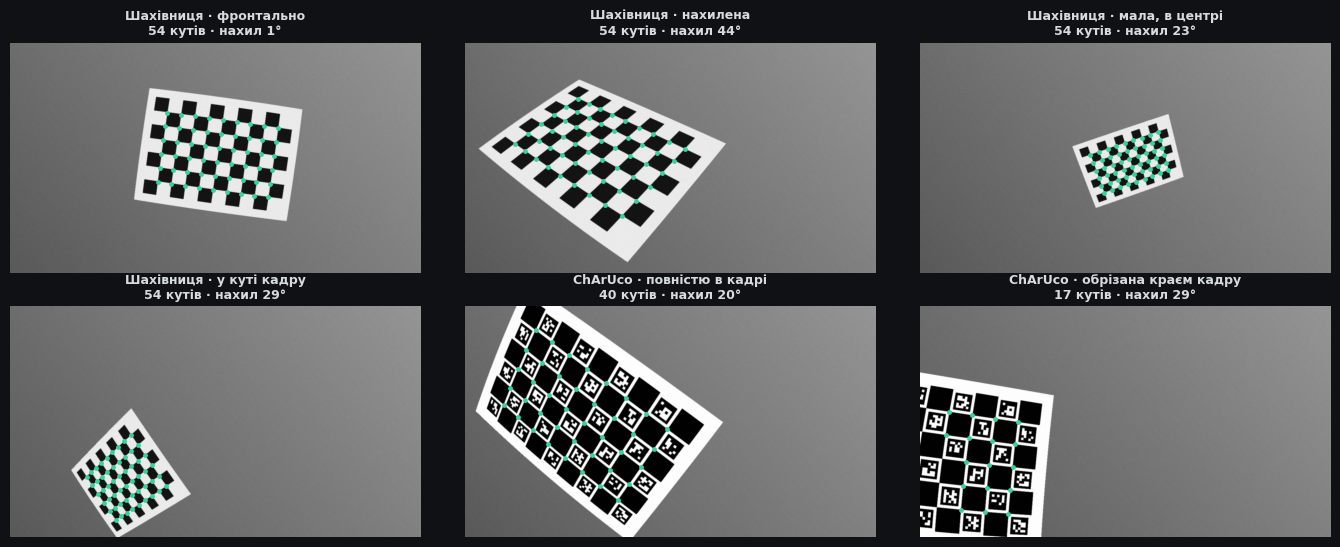

In [54]:
@dataclass
class View:
    kind: str
    frame: np.ndarray
    object_points: np.ndarray   # (N, 3) у системі дошки, м
    image_points: np.ndarray    # (N, 2) px
    tilt: float                 # нахил дошки до сенсора, °


SUBPIX = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 40, 1e-3)
CH_DETECTOR = cv2.aruco.CharucoDetector(CH_BOARD)
MIN_CHARUCO_CORNERS = 8


def detect(kind, frame):
    '''(object_points, image_points) або None, якщо мішень не знайдено.'''
    if kind == "chessboard":
        ok, pts = cv2.findChessboardCorners(frame, CORNERS, cv2.CALIB_CB_ADAPTIVE_THRESH | cv2.CALIB_CB_NORMALIZE_IMAGE)
        if not ok:
            ok, pts = cv2.findChessboardCornersSB(frame, CORNERS)      # повільніший, але надійніший запасний варіант
        if not ok:
            return None
        pts = cv2.cornerSubPix(frame, pts.astype(np.float32), (7, 7), (-1, -1), SUBPIX)
        return OBJ_CHESS, pts.reshape(-1, 2)
    corners, ids, _, _ = CH_DETECTOR.detectBoard(frame)
    if ids is None or len(ids) < MIN_CHARUCO_CORNERS or CH_BOARD.checkCharucoCornersCollinear(ids):
        return None
    obj, img = CH_BOARD.matchImagePoints(corners, ids)
    img = cv2.cornerSubPix(frame, img.astype(np.float32), (7, 7), (-1, -1), SUBPIX)
    return obj.reshape(-1, 3).astype(np.float32), img.reshape(-1, 2)


BOARD_CORNERS = {"chessboard": OBJ_CHESS, "charuco": CH_BOARD.getChessboardCorners()}


def visible_share(kind, r, t, margin=12):
    '''Яка частка кутів дошки потрапляє в кадр (за істинною моделлю) — щоб не рендерити марні пози.'''
    p = cv2.projectPoints(BOARD_CORNERS[kind], cv2.Rodrigues(r)[0], t, K_TRUE, DIST_TRUE)[0].reshape(-1, 2)
    inside = (p[:, 0] > margin) & (p[:, 0] < W - margin) & (p[:, 1] > margin) & (p[:, 1] < H - margin)
    return inside.mean()


def shoot(kind, tilt_range, offset_range, z_range, count, allow_partial=False, max_tries=400):
    '''count кадрів із випадковими позами в заданих межах; лишаємо ті, де мішень видно й знайдено.'''
    views = []
    for _ in range(max_tries):
        if len(views) == count:
            return views
        tilt, off = rng.uniform(*tilt_range), rng.uniform(*offset_range)
        ang = rng.uniform(0, 2 * np.pi)
        center = (W / 2 + off * W / 2 * np.cos(ang), H / 2 + off * H / 2 * np.sin(ang))
        r, t = pose(kind, tilt, rng.uniform(0, 360), rng.uniform(-40, 40), center, rng.uniform(*z_range))
        if visible_share(kind, r, t) < (0.35 if allow_partial else 1.0):
            continue
        frame = render(kind, r, t)
        found = detect(kind, frame)
        if found is not None:
            views.append(View(kind, frame, *found, tilt))
    raise RuntimeError(f"{kind}: за {max_tries} спроб знайдено лише {len(views)} кадрів — розшир межі поз")


def show_views(views, titles, ncols=3):
    rows = -(-len(views) // ncols)
    fig, axes = plt.subplots(rows, ncols, figsize=(4.6 * ncols, 2.75 * rows))
    for ax, v, title in zip(axes.ravel(), views, titles):
        ax.imshow(v.frame, cmap="gray", vmin=0, vmax=255)
        ax.scatter(*v.image_points.T, s=6, c=EMERALD)
        ax.set_title(f"{title}\n{len(v.image_points)} кутів · нахил {v.tilt:.0f}°", fontsize=9)
        ax.set_axis_off(); ax.grid(False)
    for ax in axes.ravel()[len(views):]:
        ax.set_axis_off()
    plt.tight_layout(); plt.show()


reseed(2)
samples = [shoot("chessboard", (0, 2), (0, 0.1), (0.7, 0.8), 1)[0],
           shoot("chessboard", (35, 45), (0.3, 0.6), (0.5, 0.7), 1)[0],
           shoot("chessboard", (15, 30), (0, 0.05), (1.2, 1.3), 1)[0],
           shoot("chessboard", (15, 30), (0.6, 0.7), (0.85, 0.95), 1)[0],
           shoot("charuco", (20, 30), (0.3, 0.5), (0.5, 0.6), 1)[0],
           shoot("charuco", (20, 30), (0.95, 1.05), (0.45, 0.5), 1, allow_partial=True)[0]]
show_views(samples, ["Шахівниця · фронтально", "Шахівниця · нахилена", "Шахівниця · мала, в центрі",
                     "Шахівниця · у куті кадру", "ChArUco · повністю в кадрі", "ChArUco · обрізана краєм кадру"])

## 3 · П'ять наборів кадрів

Один «правильний» набір і кілька «неправильних» — по одному на кожну помилку зі слайда. Усі зняті тією самою віртуальною камерою.

| Набір | Що в ньому | Помилка зі слайда |
|---|---|---|
| **GOOD** | 48 кадрів, нахил 10–45°, дошка по всьому кадру | — (еталон) |
| **MILD** | 48 кадрів по всьому кадру, але нахили лише 2–15° — «як зазвичай знімають з рук» | слабкі нахили; разом із GOOD — «замало знімків» (розділ 5) |
| **CENTER** | 12 кадрів, нахили як у GOOD, але дошка мала й лише в центрі | «дошка лише в центрі» |
| **FRONTAL** | 12 кадрів по всьому кадру, але всі майже фронтальні (нахил < 2°) | «один і той самий кут» |
| **CHARUCO** | 12 кадрів ChArUco, частина обрізана краєм кадру | покриття кутів кадру |

GOOD і MILD великі (48 кадрів) навмисно: у розділі 5 з них багато разів беремо випадкові підмножини, і великий пул не дає підмножинам надто перекриватися.

**Покриття кадру** — яка частка клітинок сітки 8×6 поверх зображення містить хоч один знайдений кут. Порожні краї означають, що дисторсію там нема з чого оцінити.

**Покроково — п'ять наборів і покриття:**

1. `reseed(3)`, потім п'ять викликів `shoot()` з параметрами з таблиці вище (нахил, зсув, відстань, кількість кадрів). Разом 132 кадри.
2. `coverage()` ділить кадр на сітку 8×6 і рахує, у скількох клітинках є хоча б один знайдений кут.
3. Для кожного набору друкуємо кількість кадрів, фактичний діапазон нахилів і покриття.
4. Теплові карти показують, де в кадрі є кути: чим яскравіша клітинка, тим більше в ній точок.

132 кадрів відрендерено й розпізнано за 8 с

GOOD     48 кадрів · нахил 10.6–44.0° · покриття кадру  85 %
MILD     48 кадрів · нахил  2.5–14.8° · покриття кадру  90 %
CENTER   12 кадрів · нахил 14.4–40.4° · покриття кадру  12 %
FRONTAL  12 кадрів · нахил  0.3– 2.0° · покриття кадру  56 %
CHARUCO  12 кадрів · нахил 12.5–44.0° · покриття кадру  85 %


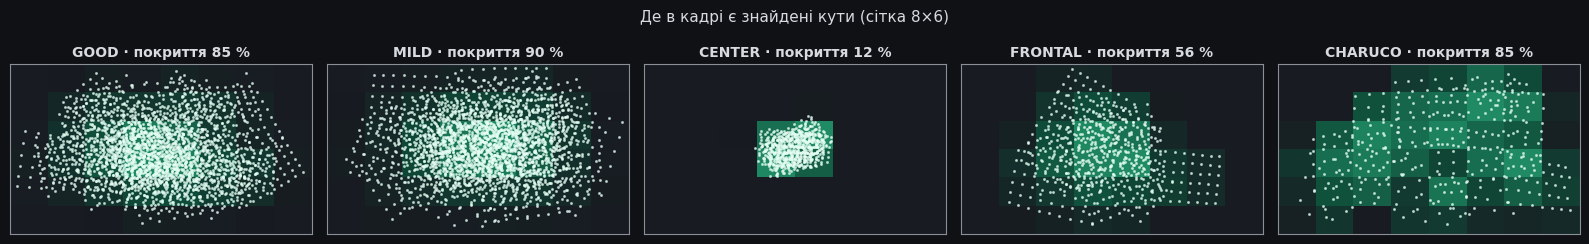

In [58]:
reseed(3)
started = time.perf_counter()
SETS = {"GOOD":    shoot("chessboard", (10, 45), (0.0, 0.75), (0.5, 0.95), 48),
        "MILD":    shoot("chessboard", (2, 15),  (0.0, 0.75), (0.5, 0.95), 48),
        "CENTER":  shoot("chessboard", (10, 45), (0.0, 0.08), (1.05, 1.35), 12),
        "FRONTAL": shoot("chessboard", (0, 2),   (0.0, 0.75), (0.5, 0.95), 12),
        "CHARUCO": shoot("charuco",    (10, 45), (0.3, 1.05), (0.45, 0.7), 12, allow_partial=True)}
print(f"{sum(len(v) for v in SETS.values())} кадрів відрендерено й розпізнано за {time.perf_counter() - started:.0f} с\n")

COVERAGE_GRID = (8, 6)


def coverage(views):
    '''Частка клітинок сітки COVERAGE_GRID з хоча б одним кутом і сама сітка лічильників.'''
    xy = np.vstack([v.image_points for v in views])
    col = np.clip((xy[:, 0] / W * COVERAGE_GRID[0]).astype(int), 0, COVERAGE_GRID[0] - 1)
    row = np.clip((xy[:, 1] / H * COVERAGE_GRID[1]).astype(int), 0, COVERAGE_GRID[1] - 1)
    counts = np.zeros(COVERAGE_GRID[::-1], int)
    np.add.at(counts, (row, col), 1)
    return (counts > 0).mean(), counts


for name, views in SETS.items():
    tilts = [v.tilt for v in views]
    print(f"{name:8s} {len(views):2d} кадрів · нахил {min(tilts):4.1f}–{max(tilts):4.1f}° "
          f"· покриття кадру {coverage(views)[0] * 100:3.0f} %")

fig, axes = plt.subplots(1, 5, figsize=(16, 2.6))
for ax, (name, views) in zip(axes, SETS.items()):
    share, counts = coverage(views)
    ax.imshow(counts, cmap=GREEN_CMAP, vmin=0, vmax=max(1, counts.max()), extent=(0, W, H, 0))
    xy = np.vstack([v.image_points for v in views])
    ax.scatter(xy[:, 0], xy[:, 1], s=1.5, c="#e6fff5", alpha=0.6)
    ax.set_title(f"{name} · покриття {share * 100:.0f} %", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Де в кадрі є знайдені кути (сітка 8×6)", fontsize=11)
plt.tight_layout(); plt.show()

## 4 · Калібрування і помилка проти істини

`calibrate` — `cv2.calibrateCameraExtended` на списку кадрів: те саме, що `cv2.calibrateCamera`, але додатково повертає σ кожного параметра і RMS перепроекції окремо для кожного кадру. Обидва числа доступні й на реальній камері, тож знадобляться в паспорті. `ray_error` — та сама метрика на весь ноутбук: для сітки пікселів беремо промінь за **істинною** моделлю і за **оціненою** і міряємо кут між ними в мрад. Її RMS по кадру — «помилка моделі», максимум — «промах у найгіршому кутку».

Для контрасту поруч завжди друкуємо **RMS перепроекції** — те єдине число, яке повертає `cv2.calibrateCamera` і на яке зазвичай дивляться.

**Покроково — калібрування й метрика:**

1. `calibrate()` викликає `cv2.calibrateCameraExtended` і повертає `K`, дисторсію, RMS перепроекції, σ кожного параметра (`std`: `fx, fy, cx, cy, k1, k2, p1, p2, k3, …`) і RMS окремо для кожного кадру (`per_view`).
2. `ERR_GRID` — сітка пікселів із кроком 16 px, 80×45 = 3600 точок по всьому кадру.
3. `rays(k, dist)` переводить кожен піксель сітки в одиничний вектор напрямку за заданою моделлю. `RAYS_TRUE` — те саме для істинної моделі.
4. `ray_error()` — кут між істинним і оціненим променем, у мрад, для кожної точки сітки. Якщо ітерація розійшлася (NaN), ставимо 1000 мрад.
5. `summary()` збирає `rms_px`, `fx`, похибку `fx` і RMS та максимум промаху по кадру.
6. `show_error_map()` малює карту промаху із цими числами в заголовку.
7. **Еталон:** калібруємо на всіх кадрах GOOD. Друкуємо `fx`, RMS, промах, `k1..k3` порівняно з істиною, похибку головної точки поруч із σ від OpenCV і діапазон RMS по кадрах.

GOOD, усі 48 кадрів:  fx = 999.3 px (істина 1000)   RMS перепроекції 0.126 px
промах променя: RMS 0.78 мрад, максимум 1.44 мрад
k1..k3 оцінка: [-0.2507  0.0925 -0.0199]  істина: [-0.25   0.09  -0.016]
головна точка: cx -0.31 px (σ від OpenCV ±0.47), cy -0.68 px (±0.39);  fx ±0.33 px
RMS перепроекції по кадрах: 0.023–0.289 px


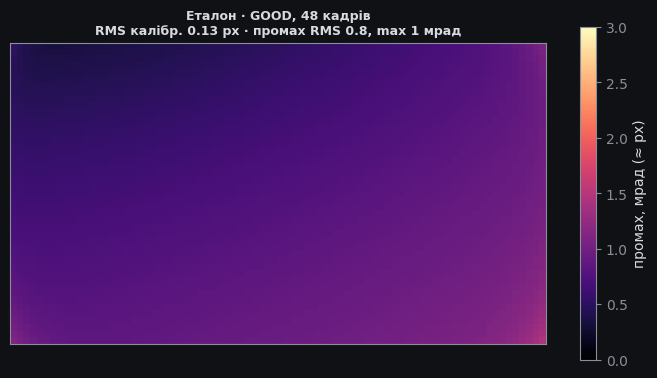

In [61]:
def calibrate(views, flags=0):
    '''K, дисторсія, RMS перепроекції, σ параметрів (fx, fy, cx, cy, k1, k2, p1, p2, k3, …)
    і RMS перепроекції кожного кадру — з cv2.calibrateCameraExtended.'''
    rms, k, dist, _, _, std, _, per_view = cv2.calibrateCameraExtended(
        [v.object_points for v in views], [v.image_points for v in views], (W, H), None, None, flags=flags)
    return {"K": k, "dist": dist.ravel(), "rms": float(rms), "std": std.ravel(), "per_view": per_view.ravel()}


ERR_STEP = 16
_gx, _gy = np.meshgrid(np.arange(ERR_STEP // 2, W, ERR_STEP), np.arange(ERR_STEP // 2, H, ERR_STEP))
ERR_GRID = np.dstack([_gx, _gy]).reshape(-1, 2).astype(np.float32)


def rays(k, dist):
    xy = undistort_normalized(ERR_GRID, k, dist)
    d = np.column_stack([xy, np.ones(len(xy))])
    return d / np.linalg.norm(d, axis=1, keepdims=True)


RAYS_TRUE = rays(K_TRUE, DIST_TRUE)


def ray_error(k, dist):
    '''Кут між істинним і оціненим променем для кожного пікселя сітки, мрад — карта (rows, cols).'''
    cos = np.clip(np.sum(rays(k, dist) * RAYS_TRUE, axis=1), -1, 1)
    err = np.arccos(cos) * 1000
    return np.nan_to_num(err, nan=1e3).reshape(_gx.shape)


def summary(cal):
    err = ray_error(cal["K"], cal["dist"])
    return {"rms_px": cal["rms"], "fx": cal["K"][0, 0], "fx_err": cal["K"][0, 0] - FX_TRUE,
            "err_rms": float(np.sqrt(np.mean(err ** 2))), "err_max": float(err.max()), "err_map": err}


def show_error_map(ax, cal, title, vmax=20):
    s = summary(cal)
    im = ax.imshow(s["err_map"], cmap="magma", vmin=0, vmax=vmax, extent=(0, W, H, 0))
    ax.set_title(f"{title}\nRMS калібр. {s['rms_px']:.2f} px · промах RMS {s['err_rms']:.1f}, "
                 f"max {s['err_max']:.0f} мрад", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return im


reference = calibrate(SETS["GOOD"])
s = summary(reference)
print(f"GOOD, усі {len(SETS['GOOD'])} кадрів:  fx = {s['fx']:.1f} px (істина {FX_TRUE:.0f})   "
      f"RMS перепроекції {s['rms_px']:.3f} px")
print(f"промах променя: RMS {s['err_rms']:.2f} мрад, максимум {s['err_max']:.2f} мрад")
print("k1..k3 оцінка:", np.round(reference["dist"][[0, 1, 4]], 4), " істина:", DIST_TRUE[[0, 1, 4]])
sd, kr = reference["std"], reference["K"]
print(f"головна точка: cx {kr[0, 2] - K_TRUE[0, 2]:+.2f} px (σ від OpenCV ±{sd[2]:.2f}), "
      f"cy {kr[1, 2] - K_TRUE[1, 2]:+.2f} px (±{sd[3]:.2f});  fx ±{sd[0]:.2f} px")
print(f"RMS перепроекції по кадрах: {reference['per_view'].min():.3f}–{reference['per_view'].max():.3f} px")

fig, ax = plt.subplots(figsize=(7, 3.8))
im = show_error_map(ax, reference, f"Еталон · GOOD, {len(SETS['GOOD'])} кадрів", vmax=3)
plt.colorbar(im, ax=ax, label="промах, мрад (≈ px)"); plt.tight_layout(); plt.show()

Рівний фон менше 1.5 мрад на еталоні — це не дисторсія, а похибка головної точки. `cx` і `cy` відхиляються від істини на кілька десятих пікселя, і σ, яку повертає OpenCV (≈ 0.4–0.5 px), каже те саме: зсув статистичний, а не баг рендера. Детектор кутів тут незміщений. Головна точка частково «змішується» з тангенціальною дисторсією `p1`, `p2`, тому навіть 48 кадрів не стискають її точніше. Такий зсув повертає всі промені майже однаково і не має структури на карті. Усе, що далі матиме структуру — плями, кільця, яскраві кути, — це вже помилки моделі дисторсії й фокусної.

## 5 · Помилка 1 — замало знімків

Беремо випадкові `n` кадрів із набору, калібруємо, повторюємо 12 разів для кожного `n`. Робимо це для двох наборів по 48 кадрів: GOOD (нахили 10–45°) і MILD (нахили 2–15°). Дивимось на розкид `fx` між повторами і на помилку моделі, а поруч — на RMS перепроекції, який повертає OpenCV.

**Покроково — розкид залежно від кількості кадрів:**

1. `reseed(5)`. `sweep()`: для кожного `n` з `COUNTS` 12 разів беремо випадкову підмножину з `n` кадрів (без повторів) і калібруємо.
2. Для кожного `n` зберігаємо σ(`fx`) між повторами, медіану й квартилі промаху та медіанний RMS перепроекції.
3. Проганяємо для GOOD і MILD: 2 × 9 × 12 = 216 калібрувань.
4. Лівий графік — σ(`fx`) у лог-шкалі. Правий — справжній промах (суцільна лінія, смуга між 25-м і 75-м перцентилями) проти RMS перепроекції (пунктир).

Нюанс: підмножини беруться з одного пулу. Тому він і має 48 кадрів: при `n = 18` дві підмножини спільні в середньому лише на ~37 % (з пулом у 24 було б ~75 %), і σ(`fx`) на великих `n` не занижується штучно.

216 калібрувань за 8 с

GOOD
  n =  3   fx =  1000.1 ±    2.9 px   промах RMS  2.57 мрад   RMS калібр. 0.104 px
  n =  4   fx =   999.8 ±    0.9 px   промах RMS  3.15 мрад   RMS калібр. 0.125 px
  n =  5   fx =   999.5 ±    1.9 px   промах RMS  1.71 мрад   RMS калібр. 0.148 px
  n =  6   fx =   999.9 ±    1.5 px   промах RMS  1.58 мрад   RMS калібр. 0.127 px
  n =  8   fx =   999.0 ±    1.2 px   промах RMS  1.99 мрад   RMS калібр. 0.124 px
  n = 10   fx =   999.7 ±    0.9 px   промах RMS  0.87 мрад   RMS калібр. 0.124 px
  n = 12   fx =   999.4 ±    1.1 px   промах RMS  1.44 мрад   RMS калібр. 0.121 px
  n = 15   fx =   999.2 ±    0.9 px   промах RMS  0.95 мрад   RMS калібр. 0.122 px
  n = 18   fx =   999.2 ±    0.5 px   промах RMS  1.14 мрад   RMS калібр. 0.132 px

MILD
  n =  3   fx =  1330.5 ± 1034.4 px   промах RMS  2.54 мрад   RMS калібр. 0.056 px
  n =  4   fx =   996.9 ±    7.1 px   промах RMS  2.27 мрад   RMS калібр. 0.104 px
  n =  5   fx =  1429.6 ± 1099.2 px   промах RMS  3.

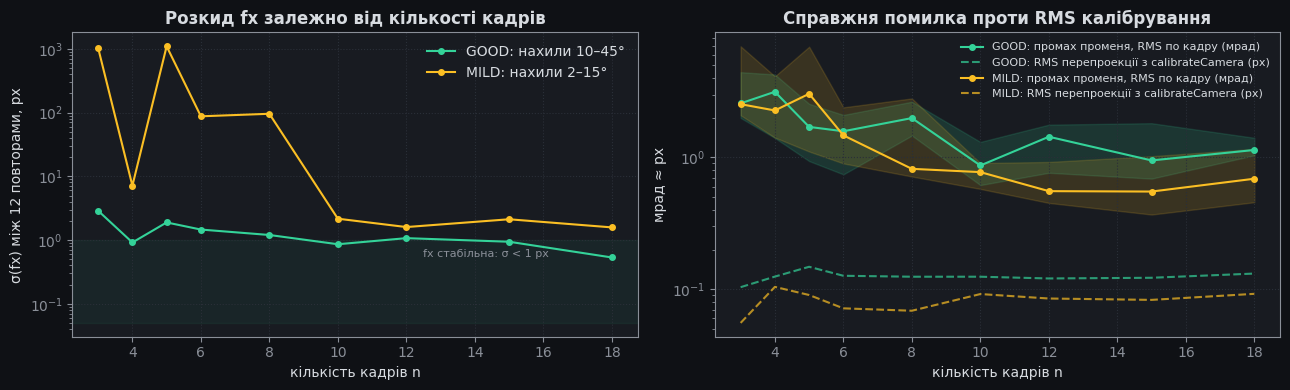

In [64]:
REPEATS = 12


def sweep(views, counts, repeats=REPEATS):
    rows = []
    for n in counts:
        runs = [summary(calibrate([views[i] for i in rng.choice(len(views), n, replace=False)]))
                for _ in range(repeats)]
        rows.append({"n": n, "fx": [r["fx"] for r in runs], "fx_std": float(np.std([r["fx"] for r in runs])),
                     "err": float(np.median([r["err_rms"] for r in runs])),
                     "err_q": np.percentile([r["err_rms"] for r in runs], [25, 75]),
                     "rms": float(np.median([r["rms_px"] for r in runs]))})
    return rows


COUNTS = [3, 4, 5, 6, 8, 10, 12, 15, 18]
reseed(5)
started = time.perf_counter()
SWEEPS = {name: sweep(SETS[name], COUNTS) for name in ("GOOD", "MILD")}
print(f"{2 * len(COUNTS) * REPEATS} калібрувань за {time.perf_counter() - started:.0f} с")
for name, rows in SWEEPS.items():
    print(f"\n{name}")
    for row in rows:
        print(f"  n = {row['n']:2d}   fx = {np.mean(row['fx']):7.1f} ± {row['fx_std']:6.1f} px"
              f"   промах RMS {row['err']:5.2f} мрад   RMS калібр. {row['rms']:.3f} px")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for name, color in (("GOOD", EMERALD), ("MILD", AMBER)):
    rows = SWEEPS[name]
    ns = [r["n"] for r in rows]
    ax1.plot(ns, [max(r["fx_std"], 0.05) for r in rows], "-o", color=color, ms=4, label=f"{name}: нахили {'10–45' if name == 'GOOD' else '2–15'}°")
    q = np.array([r["err_q"] for r in rows])
    ax2.fill_between(ns, q[:, 0], q[:, 1], color=color, alpha=0.15)
    ax2.plot(ns, [r["err"] for r in rows], "-o", color=color, ms=4, label=f"{name}: промах променя, RMS по кадру (мрад)")
    ax2.plot(ns, [r["rms"] for r in rows], "--", color=color, alpha=0.7, label=f"{name}: RMS перепроекції з calibrateCamera (px)")
ax1.set_yscale("log"); ax1.set_xlabel("кількість кадрів n"); ax1.set_ylabel("σ(fx) між 12 повторами, px")
ax1.set_title("Розкид fx залежно від кількості кадрів"); ax1.legend()
ax1.axhspan(0.05, 1, color=EMERALD, alpha=0.06); ax1.text(12.5, 0.55, "fx стабільна: σ < 1 px", fontsize=8, color=MUTED)
ax2.set_yscale("log"); ax2.set_xlabel("кількість кадрів n"); ax2.set_ylabel("мрад ≈ px")
ax2.set_title("Справжня помилка проти RMS калібрування"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Що бачимо.**

- **Кількість.** На 3–4 кадрах обидва набори дають промах 2.5–3.5 мрад — утричі більший, ніж на 10+ кадрах. MILD на 3 кадрах ще й повністю розвалюється: σ(`fx`) сягає тисяч пікселів. Звідси правило «щонайменше 10–12 знімків».
- **Нахили.** Вони важать насамперед для **стабільності** `fx`: у MILD розкид `fx` у 2–4 рази більший, ніж у GOOD, за будь-якого `n`.
- **Несподіванка.** На великих `n` промах MILD навіть трохи нижчий. Круті нахили дають шумніші кути (RMS перепроекції GOOD ≈ 0.12 px проти ≈ 0.08 у MILD), а нахилів 2–15° тут ще вистачає, бо набір покриває весь кадр. Чесний висновок: помірних нахилів досить, якщо кадрів багато, а критично погано лише з майже фронтальними кадрами (розділ 7).
- **RMS.** В обох наборах RMS перепроекції в 8–40 разів нижчий за справжню помилку і майже не залежить від `n`: він міряє підгонку під ті самі кадри, а не точність.

## 6 · Помилка 2 — дошка лише в центрі

Однакова кількість кадрів (10), однакові нахили — але в CENTER дошка мала й лише посередині. Третя карта — ChArUco: ті самі 10 кадрів, але дошка може виходити за край кадру, тому кути є й у кутках зображення. Карта промаху показує, **де** модель бреше.

**Покроково — карта «де модель бреше»:**

1. `reseed(6)`. `repeated_runs()` робить 12 калібрувань на випадкових підмножинах по 10 кадрів і сортує їх за промахом. `typical_run()` бере з них **медіанне**, тобто типовий, а не найкращий чи найгірший випадок.
2. `REPEAT_RUNS` — усі 12 повторів для кожного набору, `RUNS` — медіанне калібрування з них. Розділи 7 і 8 беруть дані саме звідси, тому їхні цифри узгоджені.
3. Три карти промаху — GOOD, CENTER, CHARUCO, — поверх них зелені точки: де були кути під час калібрування.
4. Друкуємо `k1, k2, k3` поруч з істиною.

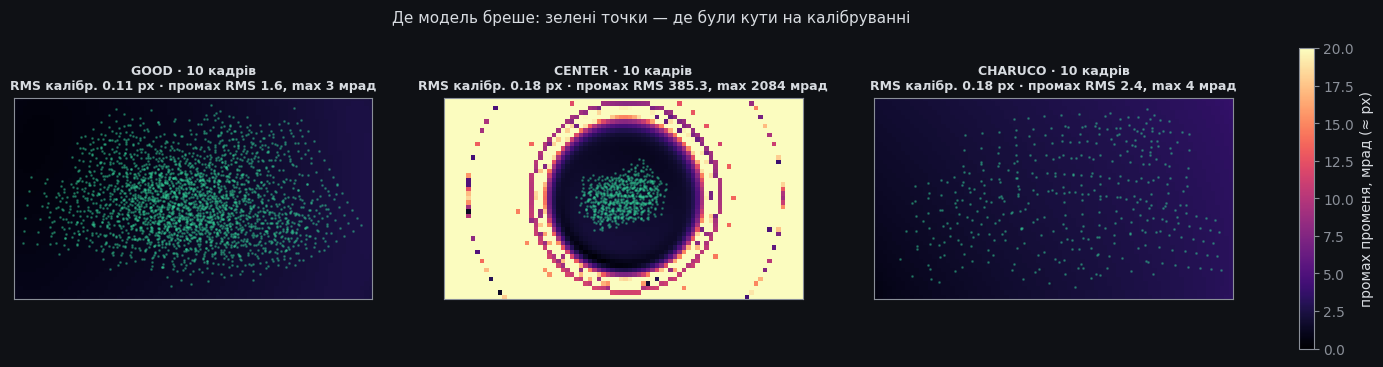

GOOD    k1 = -0.250  k2 = +0.087  k3 = -0.011     (істина -0.250, +0.090, -0.016)
CENTER  k1 = -0.281  k2 = +4.066  k3 = -97.646     (істина -0.250, +0.090, -0.016)
CHARUCO k1 = -0.247  k2 = +0.084  k3 = -0.010     (істина -0.250, +0.090, -0.016)


In [68]:
N_COMPARE = 10
reseed(6)


def repeated_runs(views, n=N_COMPARE, repeats=REPEATS):
    '''repeats калібрувань на випадкових підмножинах з n кадрів — від найточнішого до найгіршого.'''
    runs = [calibrate([views[i] for i in rng.choice(len(views), n, replace=False)]) for _ in range(repeats)]
    return sorted(runs, key=lambda c: summary(c)["err_rms"])


def typical_run(views, n=N_COMPARE, repeats=REPEATS):
    '''Калібрування з медіанною помилкою — щоб показати типовий, а не крайній випадок.'''
    runs = repeated_runs(views, n, repeats)
    return runs[len(runs) // 2]


# усі повтори зберігаємо: розділ 7 показує їхній розкид, розділ 8 — медіанне калібрування з них же
REPEAT_RUNS = {name: repeated_runs(SETS[name]) for name in SETS}
RUNS = {name: runs[len(runs) // 2] for name, runs in REPEAT_RUNS.items()}

fig, axes = plt.subplots(1, 3, figsize=(17, 3.9))
for ax, name in zip(axes, ("GOOD", "CENTER", "CHARUCO")):
    im = show_error_map(ax, RUNS[name], f"{name} · {N_COMPARE} кадрів", vmax=20)
    xy = np.vstack([v.image_points for v in SETS[name]])
    ax.scatter(xy[:, 0], xy[:, 1], s=1, c=EMERALD, alpha=0.35)
fig.colorbar(im, ax=axes, label="промах променя, мрад (≈ px)", fraction=0.025)
fig.suptitle("Де модель бреше: зелені точки — де були кути на калібруванні", fontsize=11)
plt.show()

for name in ("GOOD", "CENTER", "CHARUCO"):
    d = RUNS[name]["dist"]
    print(f"{name:7s} k1 = {d[0]:+.3f}  k2 = {d[1]:+.3f}  k3 = {d[4]:+.3f}     (істина {DIST_TRUE[0]:+.3f}, {DIST_TRUE[1]:+.3f}, {DIST_TRUE[4]:+.3f})")

**Що бачимо.** Там, де були кути, всі три моделі точні.

- **CENTER.** `k2` і `k3` тут ніщо не тримає, вони підганяються під шум: `k3` ≈ −95 замість −0.016. Уже за межами плями з кутами промах сягає десятків мрад, а в кутах кадру — сотень, тобто сотні метрів на 1 км. RMS перепроекції при цьому 0.18 px, цілком «прийнятний».
- **ChArUco.** Карта рівна, без плям, хоча частина кадрів обрізана краєм: кути дошки дотягуються до країв кадру, і `k1..k3` виходять близькими до істини. За точністю ChArUco тут на рівні шахівниці GOOD, не краща. Її перевага в тому, що придатним стає навіть кадр, де дошку видно частково.

## 7 · Помилка 3 — один і той самий кут

Чому фронтальні кадри не працюють: для дошки, паралельної сенсору, **фокусна й відстань до дошки нерозрізнювані**. Візьмемо `f` на 15 % менше і присунемо дошку на ті самі 15 % — кожен кут ляже майже в той самий піксель (лишається тільки слабкий слід від дисторсії). Тому з фронтальних кадрів `fx` не визначається взагалі — її задає шум.

**Покроково — чому фронтальні кадри вироджені:**

1. `k_alt` — та сама камера, але з хибною `f = 850`.
2. Для двох поз дошки (нахил 0° і 35°) проектуємо кути істинною камерою. Потім `solvePnP` з хибною `K` підбирає найкращу для неї позу, і ми дивимось, який залишок лишається.
3. Стрілки показують залишок, збільшений ×20. У фронтальної дошки він на рівні шуму, у нахиленої має чітку структуру.
4. Правий графік — `fx` у тих самих 12 повторах GOOD і FRONTAL з розділу 6 (`REPEAT_RUNS`). Кільцем обведено медіанне калібрування, яке піде в таблицю розділу 8.

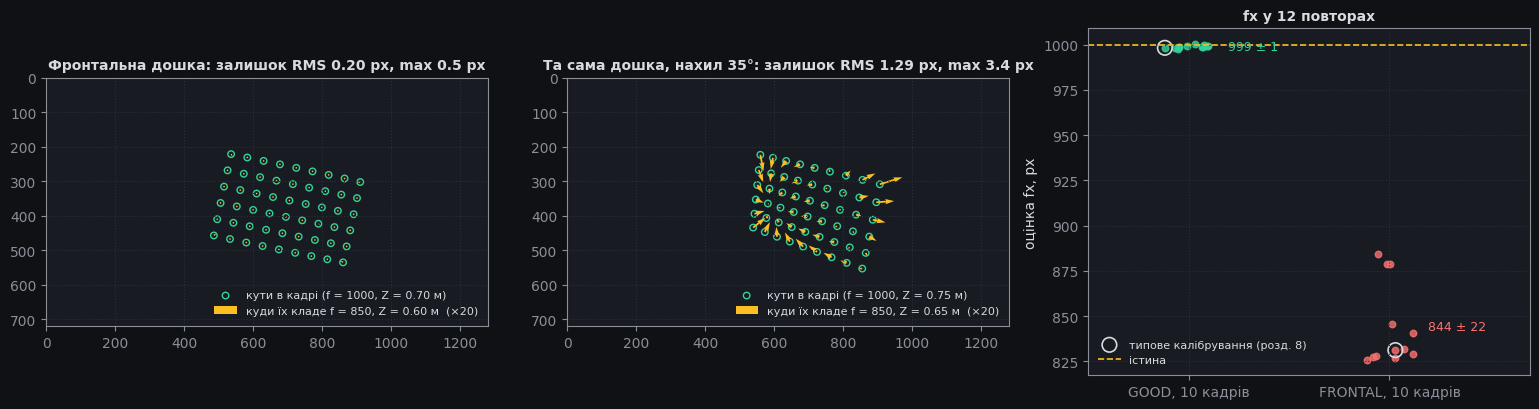

In [72]:
# ліворуч: одна й та сама дошка «знята» камерою з f = 850 замість 1000; для хибної f шукаємо найкращу позу
# (solvePnP, як це робить і calibrateCamera) і дивимось, чи лишається слід у перепроекції
k_alt = K_TRUE.copy(); k_alt[0, 0] = k_alt[1, 1] = 0.85 * FX_TRUE
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15.5, 4.2))
for ax, tilt, title in ((ax1, 0, "Фронтальна дошка"), (ax2, 35, "Та сама дошка, нахил 35°")):
    r0, t0 = pose("chessboard", tilt, 60, 12, (700, 380), 0.7)
    p_true = cv2.projectPoints(OBJ_CHESS, cv2.Rodrigues(r0)[0], t0, K_TRUE, DIST_TRUE)[0].reshape(-1, 2)
    _, rvec, tvec = cv2.solvePnP(OBJ_CHESS, p_true, k_alt, DIST_TRUE)
    p_alt = cv2.projectPoints(OBJ_CHESS, rvec, tvec, k_alt, DIST_TRUE)[0].reshape(-1, 2)
    resid = np.linalg.norm(p_alt - p_true, axis=1)
    ax.scatter(*p_true.T, s=22, facecolors="none", edgecolors=EMERALD, label=f"кути в кадрі (f = {FX_TRUE:.0f}, Z = {t0[2]:.2f} м)")
    ax.quiver(*p_true.T, *(p_alt - p_true).T * 20, angles="xy", scale_units="xy", scale=1, color=AMBER, width=0.004,
              label=f"куди їх кладе f = {0.85 * FX_TRUE:.0f}, Z = {tvec[2, 0]:.2f} м  (×20)")
    ax.set_title(f"{title}: залишок RMS {np.sqrt((resid ** 2).mean()):.2f} px, max {resid.max():.1f} px", fontsize=10)
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8)

reseed(7)
for x, (name, color) in enumerate((("GOOD", EMERALD), ("FRONTAL", RED))):
    fx = [c["K"][0, 0] for c in REPEAT_RUNS[name]]      # ті самі 12 калібрувань, що й у розділі 6
    jitter = np.full(REPEATS, x) + rng.uniform(-0.12, 0.12, REPEATS)
    ax3.scatter(jitter, fx, c=color, s=22, alpha=0.8)
    mid = REPEATS // 2                                   # медіанне за промахом — воно піде в таблицю розділу 8
    ax3.scatter(jitter[mid], fx[mid], s=110, facecolors="none", edgecolors=TXT, lw=1.2,
                label="типове калібрування (розд. 8)" if x == 0 else None)
    ax3.annotate(f"{np.mean(fx):.0f} ± {np.std(fx):.0f}", (x, np.mean(fx)), xytext=(28, 0), textcoords="offset points",
                 ha="left", va="center", fontsize=9, color=color)
ax3.axhline(FX_TRUE, color=AMBER, ls="--", lw=1.2, label="істина")
ax3.set_xticks([0, 1]); ax3.set_xticklabels([f"GOOD, {N_COMPARE} кадрів", f"FRONTAL, {N_COMPARE} кадрів"]); ax3.set_xlim(-0.5, 1.7)
ax3.set_ylabel("оцінка fx, px"); ax3.set_title(f"fx у {REPEATS} повторах", fontsize=10); ax3.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Що бачимо.** Для фронтальної дошки хибна `f = 850` з ближчою позою лишає слід 0.2 px — на рівні шуму детектора, калібрування цього не побачить. Нахил на 35° дає стрілки з чіткою структурою й залишок понад піксель: саме нахил «прив'язує» `f`.

Тому FRONTAL-набір дає `fx` із похибкою в сотні пікселів (794 ± 71 проти 999 ± 1 у GOOD), а не «трохи гірше». А його RMS перепроекції, як побачимо далі, навіть нижчий, ніж у GOOD.

## 8 · Помилка 4 — довіра до одного RMSE

Збираємо все разом: RMS перепроекції поруч зі справжньою помилкою. П'ять наборів — на однакових 10 кадрах, щоб порівняння було рівним; ще два рядки — ті самі GOOD і MILD лише на 4 кадрах, тобто «замало знімків».

**Покроково — зведена таблиця:**

1. `reseed(8)`. П'ять конфігурацій на 10 кадрах беремо з `RUNS` (GOOD, MILD, CENTER, FRONTAL, CHARUCO), ще дві — типові калібрування GOOD і MILD на 4 кадрах.
2. Для кожної друкуємо RMS перепроекції, RMS і максимум промаху та похибку `fx`.
3. Стовпчики на лог-шкалі: сірий — RMS, який друкує OpenCV; червоний — справжній промах.

набір           RMS калібр., px   промах RMS, мрад   промах max, мрад  fx − істина, px
GOOD · 10                 0.113               1.56                2.5             -1.8
MILD · 10                 0.058               1.06                2.2             +0.2
CENTER · 10               0.185             385.27             2084.1             +2.4
FRONTAL · 10              0.101              68.39              102.5           -168.8
CHARUCO · 10              0.175               2.39                3.7             +1.5
GOOD · 4                  0.170               2.48                4.3             +1.2
MILD · 4                  0.113               3.32               11.8             +6.7


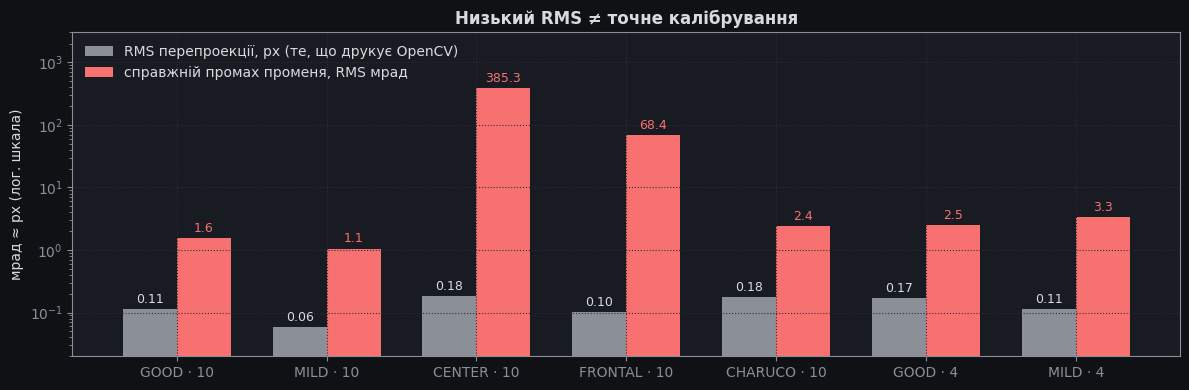

In [76]:
reseed(8)
configs = [(f"{name} · {N_COMPARE}", RUNS[name]) for name in SETS]
configs += [(f"{name} · 4", typical_run(SETS[name], n=4)) for name in ("GOOD", "MILD")]
stats = [(name, summary(cal)) for name, cal in configs]

print(f"{'набір':14s} {'RMS калібр., px':>16s} {'промах RMS, мрад':>18s} {'промах max, мрад':>18s} {'fx − істина, px':>16s}")
for name, s in stats:
    print(f"{name:14s} {s['rms_px']:16.3f} {s['err_rms']:18.2f} {s['err_max']:18.1f} {s['fx_err']:+16.1f}")

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(stats)); wdt = 0.36
ax.bar(x - wdt / 2, [s["rms_px"] for _, s in stats], wdt, color=MUTED, label="RMS перепроекції, px (те, що друкує OpenCV)")
ax.bar(x + wdt / 2, [s["err_rms"] for _, s in stats], wdt, color=RED, label="справжній промах променя, RMS мрад")
for i, (_, s) in enumerate(stats):
    ax.text(i - wdt / 2, s["rms_px"] * 1.25, f"{s['rms_px']:.2f}", ha="center", fontsize=9, color=TXT)
    ax.text(i + wdt / 2, s["err_rms"] * 1.25, f"{s['err_rms']:.1f}", ha="center", fontsize=9, color=RED)
ax.set_xticks(x); ax.set_xticklabels([n for n, _ in stats]); ax.set_ylabel("мрад ≈ px (лог. шкала)")
ax.set_yscale("log"); ax.set_ylim(0.02, 3000); ax.set_title("Низький RMS ≠ точне калібрування"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Що бачимо.** RMS перепроекції всюди «нормальний» — 0.06–0.19 px, а справжній промах різниться більш ніж на два порядки: від ≈ 1 мрад до сотень.

RMS не впорядковує калібрування за якістю:

- у FRONTAL RMS нижчий, ніж у GOOD і CHARUCO, а промах у 30–45 разів більший;
- CENTER і CHARUCO мають близький RMS, а промахи відрізняються приблизно у 180 разів.

RMS міряє, наскільки модель підігналася під **ці** кадри, а не наскільки вона правильна. Валідність калібрування — це покриття кадру, різноманітність нахилів і стабільність `fx` між підмножинами.

## 9 · Паспорт калібрування

Калібрування без паспорта в експлуатації вважається неідентифікованим. Мінімум: що калібрували, результат, якість і набір — щоб через місяць можна було зрозуміти, чи можна цьому файлу вірити. Усі метрики якості тут рахуються, а не вписуються руками: σ параметрів і RMS кожного кадру дає `calibrateCameraExtended`, розкид `fx` — розділ 5.

**Покроково — паспорт:**

1. Беремо еталонне калібрування (`reference`, усі кадри GOOD).
2. Збираємо словник: камера й режим, дата, версія OpenCV, модель дисторсії, `K`, `dist`, якість і опис набору (мішень, кількість кадрів, покриття, діапазон нахилів).
3. Якість: RMS, розкид `fx` на 10 кадрах (розділ 5), σ для `fx, fy, cx, cy`, найгірший RMS серед кадрів і кількість кадрів із RMS > 1 px. Усе це рахується, нічого не вписано руками.
4. Записуємо JSON у `artifacts/calibration_demo/` у корені репозиторію і друкуємо його.

In [40]:
s = summary(reference)
tilts = [v.tilt for v in SETS["GOOD"]]
passport = {
    "camera": {"name": "virtual-wideangle", "serial": "sim-0001", "mode": f"{W}x{H}, fixed focus"},
    "created": datetime.datetime.now().isoformat(timespec="seconds"),
    "opencv": cv2.__version__,
    "model": "pinhole + k1,k2,p1,p2,k3 (cv2.calibrateCameraExtended)",
    "K": reference["K"].round(3).tolist(),
    "dist": dict(zip(("k1", "k2", "p1", "p2", "k3"), np.round(reference["dist"], 6).tolist())),
    "quality": {"rms_px": round(s["rms_px"], 4),
                "fx_spread_px_at_10_views": round(SWEEPS["GOOD"][COUNTS.index(10)]["fx_std"], 2),
                "std_px": dict(zip(("fx", "fy", "cx", "cy"), np.round(reference["std"][:4], 3).tolist())),
                "per_view_rms_max_px": round(float(reference["per_view"].max()), 4),
                "views_over_1px": int((reference["per_view"] > 1.0).sum())},
    "dataset": {"views": len(SETS["GOOD"]), "target": f"chessboard {SQUARES[0]}x{SQUARES[1]} @ {SQUARE_M * 1000:.0f} mm",
                "coverage_share": round(coverage(SETS["GOOD"])[0], 3),
                "tilt_deg": [round(min(tilts), 1), round(max(tilts), 1)]},
}
path = OUT_DIR / f"passport_{passport['camera']['name']}_{W}x{H}.json"
path.write_text(json.dumps(passport, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"паспорт записано: {path}\n")
print(json.dumps(passport, ensure_ascii=False, indent=2))

паспорт записано: /Users/ihor.pyliavets/Documents/courses/ml/UA_COMPUTER-VISION-ADVANCED/artifacts/calibration_demo/passport_virtual-wideangle_1280x720.json

{
  "camera": {
    "name": "virtual-wideangle",
    "serial": "sim-0001",
    "mode": "1280x720, fixed focus"
  },
  "created": "2026-10-07T14:49:51",
  "opencv": "4.11.0",
  "model": "pinhole + k1,k2,p1,p2,k3 (cv2.calibrateCameraExtended)",
  "K": [
    [
      999.343,
      0.0,
      646.189
    ],
    [
      0.0,
      999.339,
      354.117
    ],
    [
      0.0,
      0.0,
      1.0
    ]
  ],
  "dist": {
    "k1": -0.250693,
    "k2": 0.092543,
    "p1": 0.000447,
    "p2": -0.000124,
    "k3": -0.019924
  },
  "quality": {
    "rms_px": 0.126,
    "fx_spread_px_at_10_views": 0.86,
    "std_px": {
      "fx": 0.328,
      "fy": 0.315,
      "cx": 0.47,
      "cy": 0.393
    },
    "per_view_rms_max_px": 0.2892,
    "views_over_1px": 0
  },
  "dataset": {
    "views": 48,
    "target": "chessboard 10x7 @ 34 mm",
    "cov

## 10 · Живий показ (опційно)

Слайдер для заняття: скільки кадрів взяти з якого набору — і одразу карта промаху й `fx`.

**Покроково — слайдер:**

1. `live()` бере `n` випадкових кадрів з обраного набору, калібрує, малює карту промаху й друкує `fx`, RMS і промах.
2. `interact` прив'язує до неї випадний список наборів і слайдер `n` (від 3 до розміру найбільшого набору).
3. Кожен рух слайдера бере нову випадкову підмножину з `rng` (тут навмисно без `reseed`). Навіть на тому самому `n` результат щоразу трохи інший, і це зручно, щоб показати розкид наживо.
4. Якщо `ipywidgets` не встановлено, клітинка просто друкує підказку.

In [44]:
try:
    from ipywidgets import interact, IntSlider, Dropdown

    def live(dataset="GOOD", n=6):
        views = SETS[dataset]
        n = min(n, len(views))
        cal = calibrate([views[i] for i in rng.choice(len(views), n, replace=False)])
        s = summary(cal)
        fig, ax = plt.subplots(figsize=(7.5, 4))
        im = show_error_map(ax, cal, f"{dataset} · {n} випадкових кадрів", vmax=20)
        plt.colorbar(im, ax=ax, label="промах, мрад"); plt.tight_layout(); plt.show()
        print(f"fx = {s['fx']:.1f} px ({s['fx_err']:+.1f} до істини) · RMS калібр. {s['rms_px']:.3f} px"
              f" · промах RMS {s['err_rms']:.1f} мрад, max {s['err_max']:.0f} мрад")

    interact(live, dataset=Dropdown(options=list(SETS), value="GOOD"),
             n=IntSlider(min=3, max=max(len(v) for v in SETS.values()), value=6, continuous_update=False));
except ImportError:
    print("ipywidgets не встановлено — слайдер пропущено (pip install ipywidgets)")

interactive(children=(Dropdown(description='dataset', options=('GOOD', 'MILD', 'CENTER', 'FRONTAL', 'CHARUCO')…

## Як повторити на власній камері

1. Замість `shoot(...)` — читаємо фото з теки й проганяємо через той самий `detect` (одна камера, одна роздільність, фокус і зум зафіксовані; на телефоні вимкнути OIS/EIS і вбудовану корекцію дисторсії).
2. Істинної `K` немає, тому `ray_error` замінюємо на **помилку на відкладених кадрах**: ховаємо чверть знімків, калібруємо на решті, для схованих шукаємо лише позу дошки (`cv2.solvePnP`) і міряємо перепроекцію. Плюс **розкид `fx` між підмножинами** — розділ 5 працює без змін, — і σ параметрів та RMS кожного кадру з `calibrateCameraExtended` (розділ 4): кадр із RMS помітно вищим за решту — кандидат на викидання.
3. Санітарна перевірка за даташитом: `f_px ≈ f_mm / pixel_pitch_mm`; розбіжність понад 15 % — калібрування хибне.
4. Паспорт — з розділу 9, з реальним серійним номером і режимом захоплення.